# Miniprojekt 2 — NASA Nearest Earth Objects (NEO)

## Cel projektu
- Zbudować model klasyfikacyjny wykrywający **potencjalnie niebezpieczne asteroidy**.
- Zaprezentować pełny pipeline: **EDA → preprocessing → modelowanie → ocena → wnioski**.


# 0. Importy i konfiguracja środowiska



In [494]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ustawienia stylu wykresów seaborn 
sns.set_theme(style="whitegrid")

# ustawienia dla matplotlib odnosnie rozmiaru wykresów
plt.rcParams['figure.figsize'] = (10,6)

# ustawienia żeby Pandas pokazywał więcej kolumn i wierszy w DataFrame
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# 1. Wczytanie danych

In [495]:

# Ścieżki do plików 
path_1 = "../data/neo.csv"       
path_2 = "../data/neo_v2.csv"  

# Wczytanie CSV do dwóch DataFrame'ów
df1 = pd.read_csv(path_1)
df2 = pd.read_csv(path_2)

# Podgląd danych
print("Tabela 1:", df1.shape)
print("Tabela 2:", df2.shape)




Tabela 1: (90836, 10)
Tabela 2: (90836, 10)


In [496]:
df1.head()

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


In [497]:
df2.head()

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


Wygląda na to, że tabelki mają taką samą zawartość. Porównuję zawartość z celu weryfikacji.

In [498]:
df1.equals(df2)

True

Pliki neo.csv i neo_v2.csv są identyczne (90 836 wierszy, 10 kolumn, dane równe w 100%), dlatego w dalszej analizie korzystam tylko z neo.csv

In [499]:
df=df1.copy

# 2. Eksploracyjna Analiza Danych (EDA)

## 2.1 Podstawowe informacje

In [500]:
# Wczytanie pliku
df = pd.read_csv("../data/neo.csv")

# Podstawowe informacje
print("Wymiary tabeli:", df.shape)
df.info() 

Wymiary tabeli: (90836, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  object 
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  object 
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), object(2)
memory usage: 5.7+ MB


### Kolumny i typy danych 

id → int64 (unikalny identyfikator)

name → object (nazwa asteroidy)

est_diameter_min, est_diameter_max → float64 (średnica w km, zakres minimalny i maksymalny)

relative_velocity → float64 (prędkość względna, km/h)

miss_distance → float64 (odległość minięcia, km)

orbiting_body → object (tu zawsze „Earth”)

sentry_object → bool (czy NASA przewiduje potencjalne zderzenie; zawsze False)

absolute_magnitude → float64 (jasność absolutna)

hazardous → bool (czy potencjalnie niebezpieczna)


In [501]:
df.describe()

,id,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude
count,9.083600e+04,90836.000000,90836.000000,90836.000000,9.083600e+04,90836.000000
mean,1.438288e+07,0.127432,0.284947,48066.918918,3.706655e+07,23.527103
std,2.087202e+07,0.298511,0.667491,25293.296961,2.235204e+07,2.894086
min,2.000433e+06,0.000609,0.001362,203.346433,6.745533e+03,9.230000
25%,3.448110e+06,0.019256,0.043057,28619.020645,1.721082e+07,21.340000
50%,3.748362e+06,0.048368,0.108153,44190.117890,3.784658e+07,23.700000
75%,3.884023e+06,0.143402,0.320656,62923.604633,5.654900e+07,25.700000
max,5.427591e+07,37.892650,84.730541,236990.128088,7.479865e+07,33.200000


In [502]:
# Średnie wartości wybranych cech z zaokrągleniem do 1 miejsca po przecinku
mean_velocity = round(df["relative_velocity"].mean(), 1)
mean_distance = round(df["miss_distance"].mean(), 1)
mean_magnitude = round(df["absolute_magnitude"].mean(), 1)

print(f"Średnia prędkość względna: {mean_velocity} km/h")
print(f"Średnia odległość minięcia: {mean_distance} km")
print(f"Średnia jasność absolutna: {mean_magnitude} mag")

Średnia prędkość względna: 48066.9 km/h
Średnia odległość minięcia: 37066546.0 km
Średnia jasność absolutna: 23.5 mag


### Wnioski

Zbiór danych zawiera około 90 tys. obiektów i 10 kolumn.

Wszystkie kolumny zawierają kompletne rekordy.

## 2.2 Analiza i przydatność kolumn
- Skoro brak braku danych to nie trzeba stosować zabiegów uzupełniajacych
- Należy jednak sprawdzić które kolumny nie wnoszą informacji.

In [503]:
df["sentry_object"].value_counts()


sentry_object
False    90836
Name: count, dtype: int64

In [504]:
df["orbiting_body"].value_counts()

orbiting_body
Earth    90836
Name: count, dtype: int64

Kolumna `sentry_object` nie wnosi informacji (zawsze False) → można usunąć.

Kolumna `orbiting_body` też nie wnosi informacji (zawsze „Earth”) → można usunąć .

In [505]:
# Usuwanie kolumn, które nic nie wnoszą
df = df.drop(columns=["sentry_object", "orbiting_body"])

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  object 
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   absolute_magnitude  90836 non-null  float64
 7   hazardous           90836 non-null  bool   
dtypes: bool(1), float64(5), int64(1), object(1)
memory usage: 4.9+ MB


Kolumny `sentry_object` i `orbiting_body` zostały usunięte, ponieważ miały stałe wartości (odpowiednio zawsze `False` i zawsze `Earth`).  
Nie wnoszą one żadnej informacji dla modelu i mogłyby wprowadzać tylko niepotrzebny szum.
Do modelowania warto użyć tylko cech numerycznych (est_diameter_*, relative_velocity, miss_distance, absolute_magnitude).

## 2.3 Analiza zmiennej docelowej (target)
- rozkład wartości `is_potentially_hazardous_asteroid`
- sprawdzenie nierównowagi klas


Liczebność klas:
hazardous
False    81996
True      8840
Name: count, dtype: int64

Procentowy udział klas:
hazardous
False    90.3
True      9.7
Name: proportion, dtype: float64


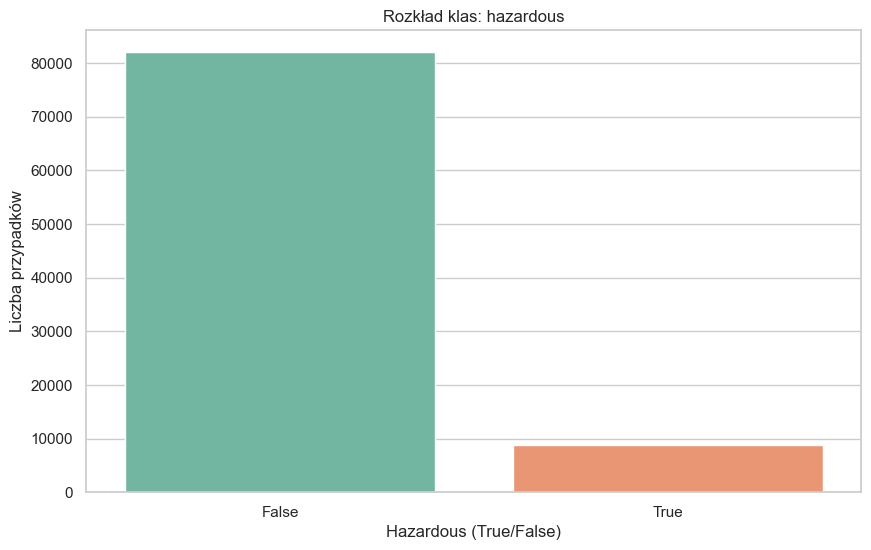

In [506]:
# Zliczenie klas
class_counts = df["hazardous"].value_counts()
class_percent = df["hazardous"].value_counts(normalize=True) * 100

print("Liczebność klas:")
print(class_counts)
print("\nProcentowy udział klas:")
print(class_percent.round(1))

# Wykres słupkowy
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index,
            dodge=False, legend=False, palette="Set2")
plt.title("Rozkład klas: hazardous")
plt.xlabel("Hazardous (True/False)")
plt.ylabel("Liczba przypadków")
plt.show()


# Wnioski

- Zmienna `hazardous` opisuje, czy asteroida jest potencjalnie niebezpieczna.
- W zbiorze danych występuje **silna nierównowaga klas**:
  - False: ~82 000 (ok. 90%)
  - True: ~8 800 (ok. 10%)
  - To oznacza, że modele predykcyjne muszą uwzględniać problem niezbalansowanych danych 

## 2.4 Analiza cech numerycznych
- histogramy / boxploty
- wartości odstające


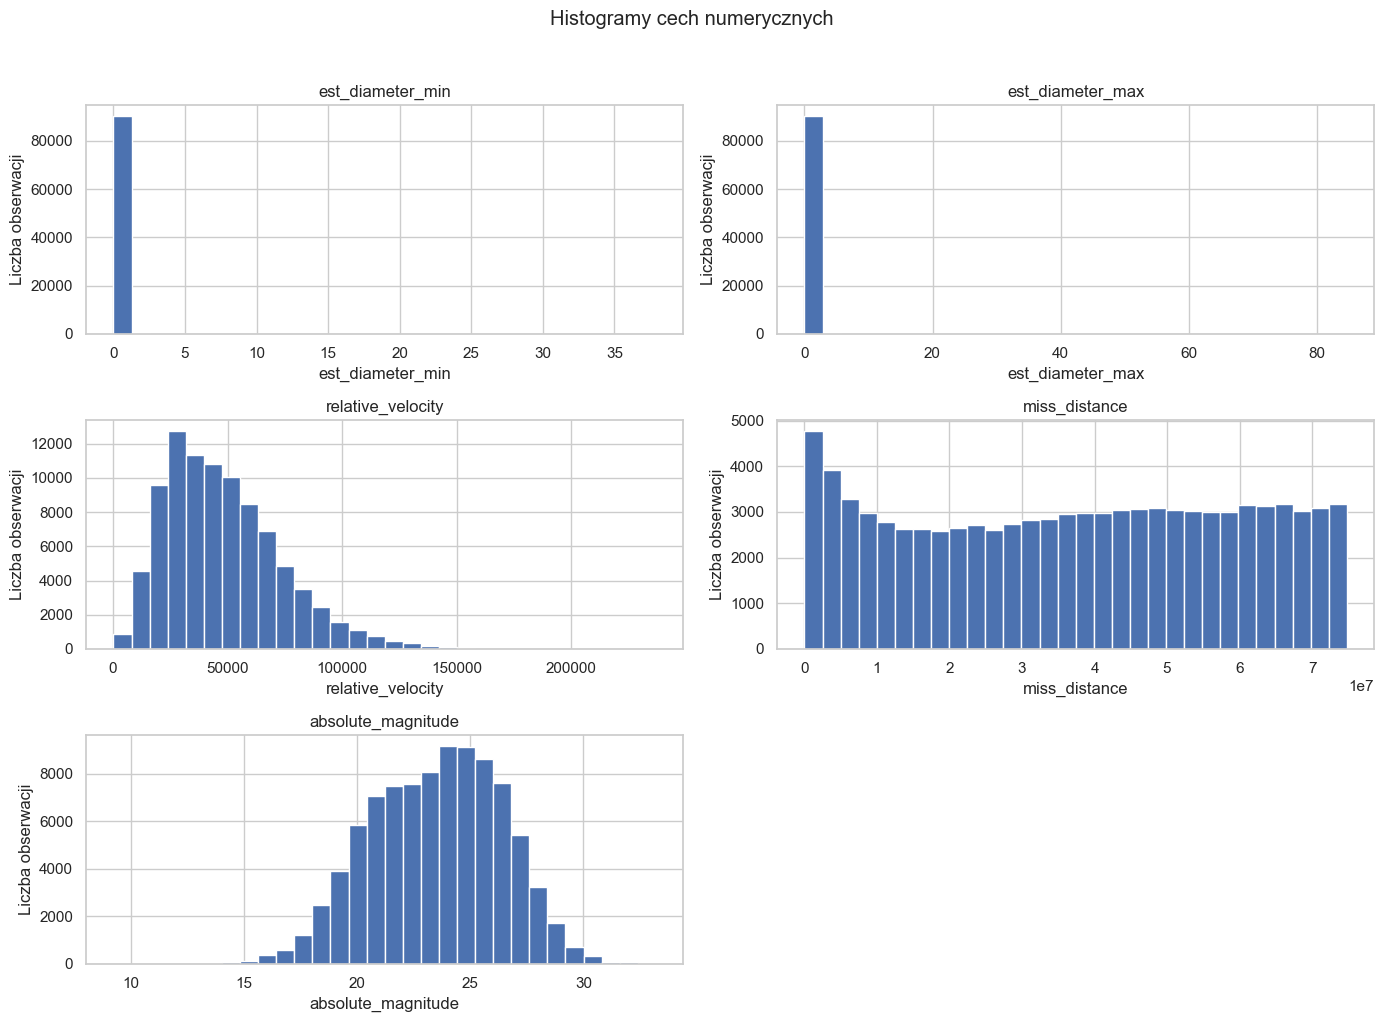

In [507]:
# Lista cech numerycznych do analizy
num_cols = ["est_diameter_min", "est_diameter_max", 
            "relative_velocity", "miss_distance", 
            "absolute_magnitude"]

axes = df[num_cols].hist(bins=30, figsize=(14,10))
plt.suptitle("Histogramy cech numerycznych", y=1.02)

# Podpisy osi dla każdej cechy
for ax, col in zip(axes.flatten(), num_cols):
    ax.set_xlabel(col)
    ax.set_ylabel("Liczba obserwacji")

plt.tight_layout()
plt.show()

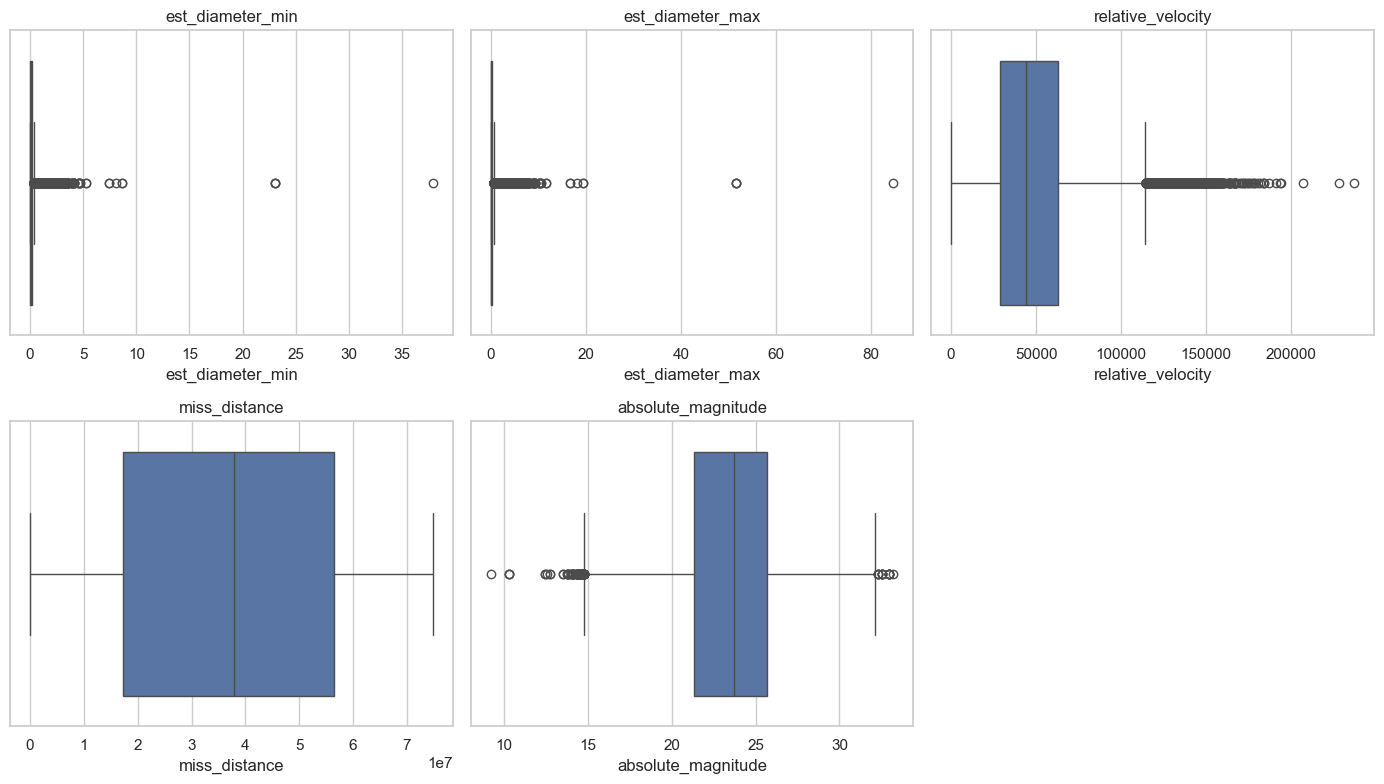

In [508]:
# 2. Boxploty dla outlierów
plt.figure(figsize=(14,8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

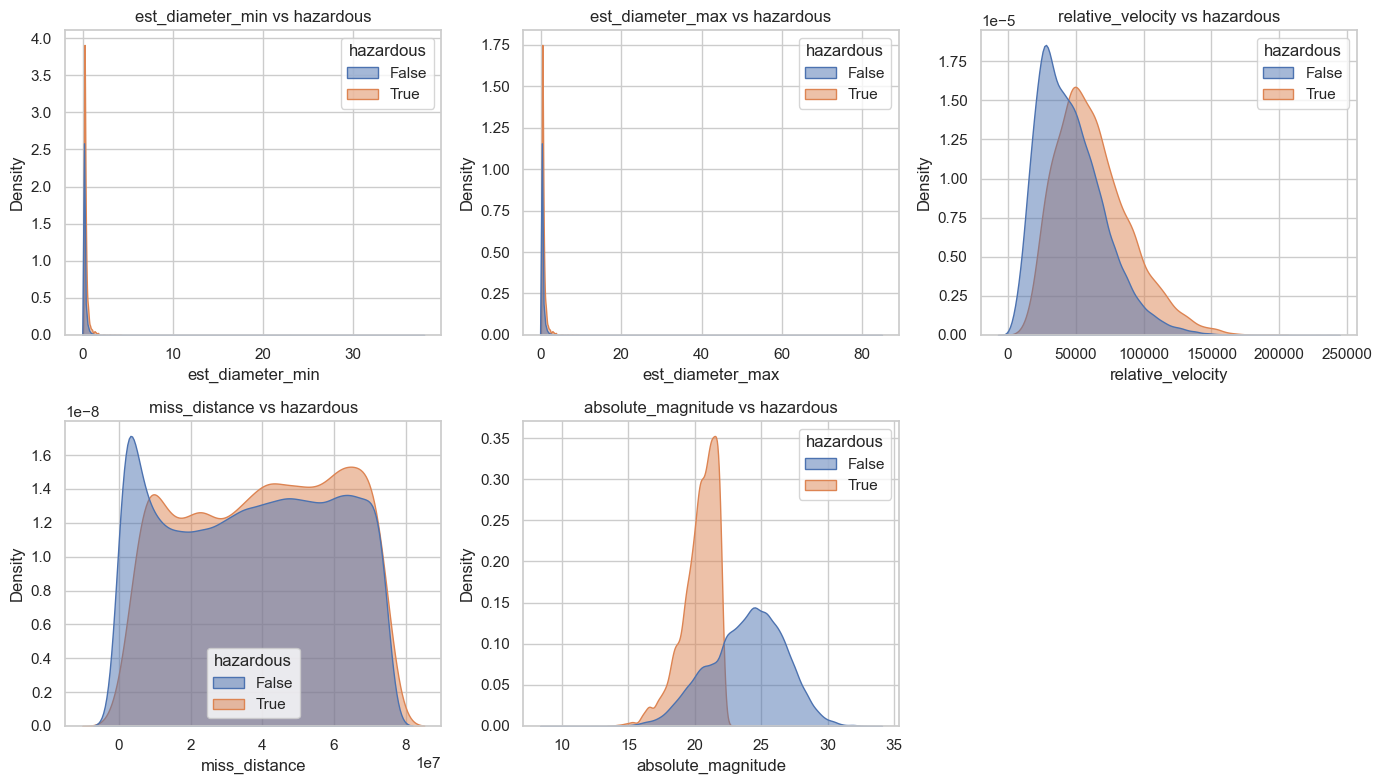

In [509]:
# 3. Porównanie rozkładów względem targetu (hazardous)
plt.figure(figsize=(14,8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.kdeplot(data=df, x=col, hue="hazardous", fill=True, common_norm=False, alpha=0.5)
    plt.title(f"{col} vs hazardous")
plt.tight_layout()
plt.show()

### Wnioski:

- **Histogramy** pokazują, że większość cech jest silnie skośna (np. średnice, odległości, prędkości).
- **Boxploty** ujawniają obecność wartości odstających (zwłaszcza w `miss_distance` i `relative_velocity`).
- **Porównanie względem `hazardous`** sugeruje, że:
  - asteroidy potencjalnie niebezpieczne częściej mają mniejszą odległość minięcia (`miss_distance`),
  - mogą różnić się też średnicą (`est_diameter_*`) i jasnością (`absolute_magnitude`).
- W dalszym preprocessingu rozważę **transformacje logarytmiczne** (lub PowerTransformer), aby zmniejszyć skośność rozkładów.


## 2.5 Korelacje
- macierz korelacji
- heatmapa


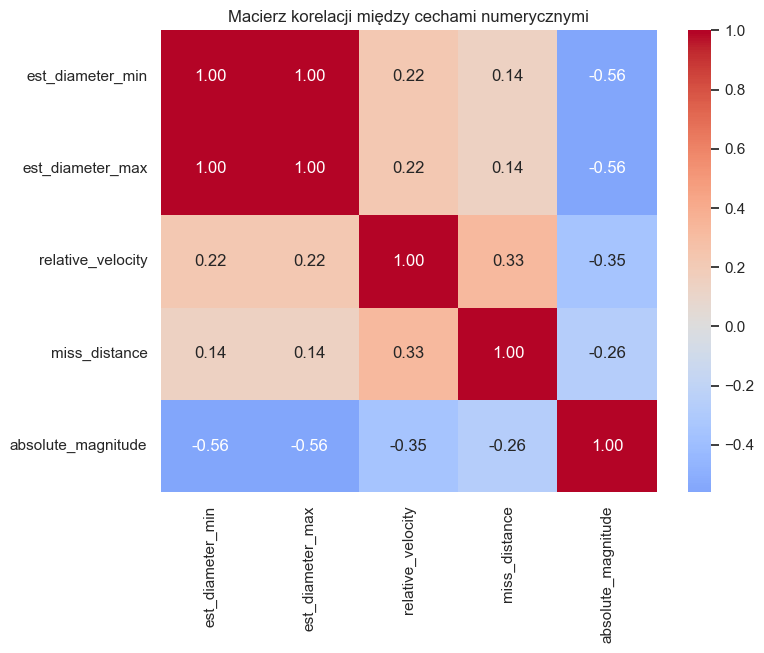

In [510]:
# Wybór tylko kolumn numerycznych (bez id oraz name, które jest tylko identyfikatorem)
num_cols = ["est_diameter_min", "est_diameter_max", 
            "relative_velocity", "miss_distance", 
            "absolute_magnitude"]

# Macierz korelacji
corr = df[num_cols].corr()

# Heatmapa korelacji
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Macierz korelacji między cechami numerycznymi")
plt.show()



- `est_diameter_min` i `est_diameter_max` są silnie skorelowane (prawie 1.0), 
  ponieważ opisują to samo zjawisko (przedział średnicy).
- `absolute_magnitude` (jasność absolutna) ma ujemną korelację z rozmiarem 
  (większe asteroidy → mniejsza jasność absolutna).
- `relative_velocity` i `miss_distance` są słabo skorelowane z innymi cechami.
- W preprocessingu można rozważyć usunięcie jednej z kolumn `est_diameter_min` / `est_diameter_max`, 
  aby zmniejszyć redundancję.


# 3. Preprocessing danych

## 3.1 Usuwanie zbędnych kolumn

In [511]:
# Usuwanie kolumn, które nie są potrzebne do modelowania, poniewaz nie niosą wartości predykcyjnej, tylko wartosci identyfikujace
# mogą wprowadzać szum (model „uczyłby się” przypadkowych wzorców)
df = df.drop(columns=['id','name'])


In [512]:
df.head()

,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,1.198271,2.679415,13569.249224,5.483974e+07,16.73,False
1,0.265800,0.594347,73588.726663,6.143813e+07,20.00,True
2,0.722030,1.614507,114258.692129,4.979872e+07,17.83,False
3,0.096506,0.215794,24764.303138,2.543497e+07,22.20,False
4,0.255009,0.570217,42737.733765,4.627557e+07,20.09,True


## 3.1 Sprawdzanie i usuwanie duplikatów

In [513]:
# Liczba duplikatów
df.duplicated().sum()


np.int64(7)

Duplikaty mogą powodować, że model będzie kilkukrotnie uczył się na identycznych obserwacjach, to sztucznie zwiększa wagę takich przypadków.
Jeśli duplikatów jest bardzo mało (np. <0.1% danych), ich obecność nie wpływa na rozkłady, ale warto je usunąć, żeby zbiór był „czysty"

In [514]:
dups = df.duplicated().sum()
perc = dups / len(df) * 100
print(f"Duplikaty: {dups} ({perc:.4f}% z {len(df)} rekordów)")

Duplikaty: 7 (0.0077% z 90836 rekordów)


W zbiorze po wstępnym czyszczeniu (usunięciu kolumn id, name, sentry_object i orbiting_body) wykryto 7 duplikatów (≈0.008% z 90 836 rekordów).To bardzo mało i nie ma istotnego wpływu na modelowanie(<0,1% danych), pomimo to zdecydowałam sie na ich usuniecie aby zbior był "czysty" i aby uniknąć powtarzania obserwacji.

In [515]:
# Policzenie duplikatów
n_dups = df.duplicated().sum()
print(f"Liczba duplikatów w zbiorze: {n_dups}")

# Wyświetlenie duplikatów 
if n_dups > 0:
    duplikaty = df[df.duplicated(keep=False)]
    display(duplikaty)

# Usunięcie duplikatów
df.drop_duplicates(inplace=True)
print(f"Liczba rekordów po usunięciu duplikatów: {len(df)}")


Liczba duplikatów w zbiorze: 7


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
4383,0.140138,0.313357,36473.191061,6.578474e+07,21.39,True
4384,0.140138,0.313357,36473.191061,6.578474e+07,21.39,True
16727,0.140138,0.313357,36419.712852,6.358959e+07,21.39,True
16728,0.140138,0.313357,36419.712852,6.358959e+07,21.39,True
29250,0.140138,0.313357,48814.898566,4.641523e+07,21.39,True
29251,0.140138,0.313357,48814.898566,4.641523e+07,21.39,True
30582,0.140138,0.313357,25338.439042,6.095792e+07,21.39,True
30583,0.140138,0.313357,25338.439042,6.095792e+07,21.39,True
48172,0.140138,0.313357,34485.841845,6.642410e+07,21.39,True
48173,0.140138,0.313357,34485.841845,6.642410e+07,21.39,True


Liczba rekordów po usunięciu duplikatów: 90829


## 3.2 Konwersje typów

W celu ujednolicenia typow do modelowania nalezy przekaształcic cechy liczbowe na float i zajać sie zmienna docelowa czyli hazardous i zamienic ją na int.

In [516]:
# Podgląd typów przed
print("PRZED:\n", df.dtypes, "\n")

# 1) Kolumny, które traktujemy jako liczbowe
num_cols = [
    'est_diameter_min', 'est_diameter_max',
    'relative_velocity', 'miss_distance', 'absolute_magnitude'
]
num_cols = [c for c in num_cols if c in df.columns]  # tylko te, które istnieją

# Prosta konwersja tekst->liczba:
# - usuwa spacje
# - zamienia przecinek na kropkę
# - zamienia na liczbę (błędne wartości staną się NaN)
for c in num_cols:
    df[c] = (
        df[c]
        .astype(str).str.strip().str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    df[c] = pd.to_numeric(df[c], errors='coerce')

# 2) Target na 0/1
if 'hazardous' in df.columns:
    df['hazardous'] = (
        df['hazardous']
        .astype(str).str.strip().str.lower()
        .map({'true':1, '1':1, 'false':0, '0':0})
        .astype('Int64')  # pozwala na NaN, jeśli coś nie pasuje
    )

# Podgląd typów po
print("PO:\n", df.dtypes)

# Szybka informacja o brakach po konwersji
na_counts = df[num_cols].isna().sum().sort_values(ascending=False)
print("\nNowe/istniejące NaN w kolumnach liczbowych:\n", na_counts.head(10))


PRZED:
 est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
absolute_magnitude    float64
hazardous                bool
dtype: object 

PO:
 est_diameter_min      float64
est_diameter_max      float64
relative_velocity     float64
miss_distance         float64
absolute_magnitude    float64
hazardous               Int64
dtype: object

Nowe/istniejące NaN w kolumnach liczbowych:
 est_diameter_min      0
est_diameter_max      0
relative_velocity     0
miss_distance         0
absolute_magnitude    0
dtype: int64


In [517]:
df.head()

,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,1.198271,2.679415,13569.249224,5.483974e+07,16.73,0
1,0.265800,0.594347,73588.726663,6.143813e+07,20.00,1
2,0.722030,1.614507,114258.692129,4.979872e+07,17.83,0
3,0.096506,0.215794,24764.303138,2.543497e+07,22.20,0
4,0.255009,0.570217,42737.733765,4.627557e+07,20.09,1


## 3.3 Skalowanie / transformacje

Z obserwacji wynika że miss_distance ma ogromne wartości (dziesiątki milionów kilometrów). W takiej sytuacji modele liniowe i metody bazujące na odległościach lepiej działają, gdy rozciągniętą zmienną przekształcimy logarytmem.

In [518]:
# Transformacja logarytmiczna miss_distance
df['log_miss_distance'] = np.log1p(df['miss_distance'])

# Podgląd starej i nowej kolumny
df[['miss_distance', 'log_miss_distance']].head()


,miss_distance,log_miss_distance
0,5.483974e+07,17.819926
1,6.143813e+07,17.933541
2,4.979872e+07,17.723500
3,2.543497e+07,17.051636
4,4.627557e+07,17.650125


Zdecydowałam sie na pozostawienie kolumny miss_distance, ponieważ może być przydatna do analizy i interpretacji wyników. 
Logarytmiczna transformacja jest przydatna w modelowaniu, ale oryginalne wartości mogą być również istotne w kontekście 
interpretacji wyników.

In [519]:
df.head()

,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous,log_miss_distance
0,1.198271,2.679415,13569.249224,5.483974e+07,16.73,0,17.819926
1,0.265800,0.594347,73588.726663,6.143813e+07,20.00,1,17.933541
2,0.722030,1.614507,114258.692129,4.979872e+07,17.83,0,17.723500
3,0.096506,0.215794,24764.303138,2.543497e+07,22.20,0,17.051636
4,0.255009,0.570217,42737.733765,4.627557e+07,20.09,1,17.650125


Niektóre cechy mają bardzo różne skale (np. relative_velocity liczone w tysiącach, absolute_magnitude w pojedynczych liczbach) dlatego należy zastosować standaryzację. Dodam też nową cechę est_diameter_avg, czyli średnią średnicę asteroidy — to może być lepsza miara rozmiaru niż samo minimum lub maksimum.

In [520]:
from sklearn.preprocessing import StandardScaler

# 1) Dodanie średniej średnicy asteroidy
df['est_diameter_avg'] = (df['est_diameter_min'] + df['est_diameter_max']) / 2

# 2) Lista kolumn numerycznych do standaryzacji
num_cols = [
    'est_diameter_min', 'est_diameter_max',
    'relative_velocity', 'miss_distance',
    'absolute_magnitude', 'est_diameter_avg',
    'log_miss_distance'  # dodana wcześniej
]

# 3) Standaryzacja (średnia = 0, odchylenie standardowe = 1)
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

# 4) Szybki podgląd po skalowaniu
df[num_cols].head()


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,est_diameter_avg,log_miss_distance
0,3.587149,3.587149,-1.363907,0.795225,-2.348647,3.587149,0.672529
1,0.463515,0.463515,1.008978,1.090430,-1.218770,0.463515,0.772412
2,1.991814,1.991814,2.616875,0.569695,-1.968566,1.991814,0.587758
3,-0.103594,-0.103594,-0.921308,-0.520317,-0.458609,-0.103594,-0.002900
4,0.427365,0.427365,-0.210724,0.412072,-1.187673,0.427365,0.523251


Zastosowano standaryzację cech liczbowych (średnia=0, odchylenie=1). W wyniku część wartości stała się ujemna, co jest naturalnym efektem tej metody i nie wpływa negatywnie na jakość modeli.

## 3.4 Balansowanie klas
Z EDA (punkt 2.3 Analiza zmiennej docelowej) wynika że klasa zagrożenia (hazardous) jest niezbalansowana czyli, że większość obserwacji ma wartość False (teraz 0  czyli bezpieczna), tylko niewielki procent to True (teraz 1 czyli zagrożenie).

hazardous
0    81996
1     8833
Name: count, dtype: Int64
hazardous
0    0.902751
1    0.097249
Name: proportion, dtype: Float64


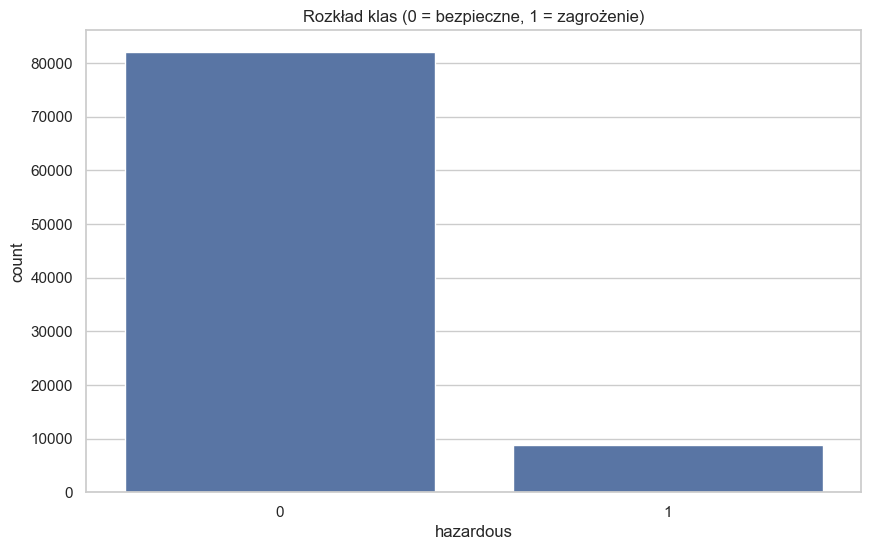

In [521]:
# Rozkład klas
print(df['hazardous'].value_counts())
print(df['hazardous'].value_counts(normalize=True))

# Wizualizacja
sns.countplot(x='hazardous', data=df)
plt.title("Rozkład klas (0 = bezpieczne, 1 = zagrożenie)")
plt.show()


Model może nauczyć się przewidywać zawsze 0 i osiągnąć np. 96% dokładności, ale nie wykryje prawdziwych zagrożeń.
Dla NASA to kluczowe, żeby wychwycić nawet rzadkie przypadki — dlatego klasy muszą być zbalansowane. Dane są niezbalansowane – przypadki zagrożenia (1) to tylko kilka procent całości. Balansowanie (wybrałam metodę SMOTE) zastosuje dopiero po podziale na train/test, aby nie „przeciekały” sztucznie wygenerowane przykłady do zbioru testowego.

# 4. Modelowanie

## 4.1 Podział na train/test

Dane zostały podzielone w proporcji 80/20 (nie 70/30) ze względu na dużą liczność zbioru (ok. 90 tys. rekordów). Dzięki temu więcej danych pozostaje do nauki modelu, co zwykle poprawia jego jakość.

In [522]:
from sklearn.model_selection import train_test_split

# Podział na cechy (X) i target (y)
X = df.drop(columns=['hazardous'])
y = df['hazardous']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Rozmiar zbioru treningowego:", X_train.shape[0])
print("Rozmiar zbioru testowego:", X_test.shape[0])
print("\nRozkład klas w y_train:")
print(y_train.value_counts(normalize=True) * 100)
print("\nRozkład klas w y_test:")
print(y_test.value_counts(normalize=True) * 100)


Rozmiar zbioru treningowego: 72663
Rozmiar zbioru testowego: 18166

Rozkład klas w y_train:
hazardous
0    90.275656
1     9.724344
Name: proportion, dtype: Float64

Rozkład klas w y_test:
hazardous
0    90.273038
1     9.726962
Name: proportion, dtype: Float64


Ponieważ klasa hazardous = 1 była znacznie rzadsza, zastosowałam technikę SMOTE na zbiorze treningowym. Dzięki temu liczba przykładów klasy mniejszościowej została wyrównana, co umożliwiło modelowi skuteczniejsze uczenie się rozpoznawania niebezpiecznych asteroidów. Zbiór testowy pozostał niezmieniony, aby ocena odzwierciedlała realne proporcje klas. W tym celu zainstlowałam odpowiednie biblioteki.

In [523]:
!pip install imbalanced-learn



[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [524]:
import imblearn
print(imblearn.__version__)


0.14.0


In [525]:
from imblearn.over_sampling import SMOTE

# SMOTE tylko na zbiorze treningowym
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Rozkład klas przed SMOTE:")
print(y_train.value_counts())

print("\nRozkład klas po SMOTE:")
print(y_train_res.value_counts())


Rozkład klas przed SMOTE:
hazardous
0    65597
1     7066
Name: count, dtype: Int64

Rozkład klas po SMOTE:
hazardous
0    65597
1    65597
Name: count, dtype: Int64


Po zastosowaniu techniki SMOTE na zbiorze treningowym, liczba przykładów obu klas została wyrównana (65 597 dla klasy 0 i 65 597 dla klasy 1). Dzięki temu model będzie miał lepszą zdolność do rozpoznawania potencjalnie niebezpiecznych asteroid

## 4.2 Model 1 — Logistic Regression

Wybrałam jako pierwszy ponieważ to prosty i klasyczny model binarnej klasyfikacji.
Jest dobrym punktem odniesienia („baseline”) dla bardziej złożonych metod.
Dzięki współczynnikom możemy łatwo interpretować, które cechy zwiększają prawdopodobieństwo, że asteroida jest zagrożeniem.

In [526]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 1) Trening modelu na zbiorze zbalansowanym (po SMOTE)
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_res, y_train_res)

# 2) Predykcja na zbiorze testowym (bez SMOTE!)
y_pred = log_reg.predict(X_test)

# 3) Ocena jakości
print("Raport klasyfikacji:")
print(classification_report(y_test, y_pred, digits=3))

print("Macierz pomyłek:")
print(confusion_matrix(y_test, y_pred))


Raport klasyfikacji:
              precision    recall  f1-score   support

         0.0      0.988     0.774     0.868     16399
         1.0      0.304     0.916     0.456      1767

    accuracy                          0.788     18166
   macro avg      0.646     0.845     0.662     18166
weighted avg      0.922     0.788     0.828     18166

Macierz pomyłek:
[[12689  3710]
 [  148  1619]]


- Ogólna trafność (accuracy)
Accuracy = 78.8%
Nie jest to najważniejsza metryka przy niezbalansowanych klasach, ale daje pogląd, że model generalnie działa.
- Klasa 0 (bezpieczne asteroidy)
Precision = 0.988 → jeśli model mówi, że asteroida jest bezpieczna, prawie zawsze ma rację.
Recall = 0.774 → z prawdziwych „bezpiecznych” asteroid ~77% zostało poprawnie wykrytych, ale 23% model uznał błędnie za zagrożenie.
- Klasa 1 (zagrożenie) – ta najważniejsza dla NASA 
- Precision = 0.304 → tylko 30% przewidzianych jako „zagrożenie” faktycznie nimi jest → dużo fałszywych alarmów.
- Recall = 0.916 → aż 91,6% rzeczywistych zagrożeń model wykrył poprawnie! → to świetny wynik, bo w tym problemie wolimy nadmiar alarmów niż przegapienie asteroidy.
-F1-score = 0.456 → średnia między precision i recall, ale tu ważniejszy jest recall.
- Macierz pomyłek:
148 asteroid zagrożonych zostało przeoczonych (false negatives).
3710 asteroid bezpiecznych uznano błędnie za zagrożenie (false positives).
W praktyce oznacza to, że model często zgłasza alarmy, ale dzięki temu rzadko przepuszcza prawdziwe zagrożenie.

### Podsumowanie modelu

Model Logistic Regression osiągnął 78,8% trafności ogólnej. Najważniejsza metryka – Recall dla klasy zagrożeń – wyniosła 91,6%, co oznacza, że model potrafi wykrywać zdecydowaną większość potencjalnie niebezpiecznych asteroid. Wadą jest niska precyzja (30%), czyli liczne fałszywe alarmy. Jednak z punktu widzenia bezpieczeństwa NASA taki kompromis jest akceptowalny: lepiej zgłosić zbyt wiele ostrzeżeń niż przeoczyć niebezpieczny obiekt. Niestety celem NASA jest również priorytetyzacja projektów badawczych, sprawdzę wiec kolejny model.

## 4.3 Model 2 — Random Forest

Kolejnym sprawdzanym modelem jest Random Forest. To model oparty na wielu drzewach decyzyjnych.
Radzi sobie dobrze z nieliniowymi zależnościami i interakcjami między cechami.
Jest mniej podatny na nadmierne dopasowanie niż pojedyncze drzewo.
Często daje lepszy kompromis między precision i recall niż modele liniowe.

In [527]:
from sklearn.ensemble import RandomForestClassifier

# 1) Trening modelu na zbiorze zbalansowanym (po SMOTE)
rf = RandomForestClassifier(
    n_estimators=100,      # liczba drzew w lesie
    random_state=42,
    n_jobs=-1              # użycie wszystkich rdzeni procesora
)
rf.fit(X_train_res, y_train_res)

# 2) Predykcja na zbiorze testowym (tak jak w poprzednim modelu, zbiorze nizbalansowanym)
y_pred_rf = rf.predict(X_test)

# 3) Ocena jakości
print("Raport klasyfikacji (Random Forest):")
print(classification_report(y_test, y_pred_rf, digits=3))

print("Macierz pomyłek (Random Forest):")
print(confusion_matrix(y_test, y_pred_rf))


Raport klasyfikacji (Random Forest):
              precision    recall  f1-score   support

         0.0      0.957     0.931     0.944     16399
         1.0      0.489     0.610     0.543      1767

    accuracy                          0.900     18166
   macro avg      0.723     0.771     0.743     18166
weighted avg      0.911     0.900     0.905     18166

Macierz pomyłek (Random Forest):
[[15273  1126]
 [  689  1078]]


### Podsumowanie modelu

- Random Forest na danych po SMOTE osiągnął accuracy = 0.90.
- Najważniejsze: Recall(1) = 0.610, co oznacza, że model wykrywa 61% zagrożeń.
- W porównaniu do Logistic Regression, Precision(1) wzrosło z 0.304 do 0.489, dzięki czemu mamy mniej fałszywych alarmów.
- F1(1) wzrósł z 0.456 do 0.543, co sugeruje lepszy kompromis między wykrywaniem a trafnością alarmów.
- Liczba FN wyniosła 689 (było 148 w LogReg), a FP 1126 (było 3710), co zwiększa ryzyko przegapienia groźnej asteroidy, ale znacząco redukuje liczbę fałszywych alarmów.

## 4.4 Model 3 — XGBoost


Wybrałam model XGBoost, ponieważ jest to wydajny algorytm drzew decyzyjnych często stosowany w klasyfikacji i dobrze radzący sobie z dużymi zbiorami danych.

In [528]:
!pip install xgboost



[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [529]:
from xgboost import XGBClassifier


# 1) Trening XGBoost na danych po SMOTE
xgb = XGBClassifier(
    n_estimators=200,       # liczba drzew
    learning_rate=0.1,      # tempo uczenia
    max_depth=6,            # maksymalna głębokość drzewa
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'   # wyłącza ostrzeżenie
)

xgb.fit(X_train_res, y_train_res)

# 2) Predykcja na zbiorze testowym (oryginalnym!)
y_pred_xgb = xgb.predict(X_test)

# 3) Ocena jakości
print("Raport klasyfikacji (XGBoost):")
print(classification_report(y_test, y_pred_xgb, digits=3))

print("Macierz pomyłek (XGBoost):")
print(confusion_matrix(y_test, y_pred_xgb))


c:\Users\annas\projekty_infoshare\jdszr20-miniprojekty-1\venv\Lib\site-packages\xgboost\training.py:183: UserWarning: [11:24:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Raport klasyfikacji (XGBoost):
              precision    recall  f1-score   support

         0.0      0.982     0.823     0.895     16399
         1.0      0.343     0.857     0.490      1767

    accuracy                          0.826     18166
   macro avg      0.662     0.840     0.693     18166
weighted avg      0.919     0.826     0.856     18166

Macierz pomyłek (XGBoost):
[[13497  2902]
 [  253  1514]]


### Interpretacja XGBoost

- Accuracy = 0.826 → trochę wyższa niż Logistic Regression (0.788), ale niższa niż Random Forest (0.90).
- Recall (1) = 0.857 → wykrywa 85,7% zagrożeń. To lepszy wynik niż Random Forest (61%), ale trochę gorszy niż Logistic Regression (91,6%).
- Precision (1) = 0.343 → tylko 34,3% przewidzianych zagrożeń faktycznie nimi było (czyli sporo fałszywych alarmów), podobnie jak Logistic - Regression (30%), ale gorzej niż Random Forest (49%).
- F1(1) = 0.490 → lepszy niż Logistic Regression (0.456) i minimalnie gorszy niż Random Forest (0.543).
- FN (false negatives) = 253 → dużo lepiej niż Random Forest (689), gorzej niż Logistic Regression (148).
- FP (false positives) = 2902 → mniej niż Logistic Regression (3710), ale więcej niż Random Forest (1126)

### Podsumowanie XGBoost

Model XGBoost osiągnął 82,6% trafności ogólnej. Recall(1) = 85,7% oznacza, że model wykrywa większość zagrożeń, choć trochę gorzej niż Logistic Regression (91,6%). W porównaniu do RandomForest znacząco zmniejszył liczbę przeoczonych zagrożeń (FN=253 vs 689), kosztem większej liczby fałszywych alarmów (FP=2902). Precision(1) spadło do 34,3%, więc ostrzeżeń jest sporo, ale kompromis F1(1)=0.490 sugeruje, że XGBoost radzi sobie lepiej niż Logistic Regression, choć ustępuje Random Forest w równowadze między recall i precision.

# 5. Ocena modeli

### Tabela macierzy pomyłek

| Model               | TN    | FP   | FN  | TP   |
| ------------------- | ----- | ---- | --- | ---- |
| Logistic Regression | 12689 | 3710 | 148 | 1619 |
| Random Forest       | 15273 | 1126 | 689 | 1078 |
| XGBoost             | 13497 | 2902 | 253 | 1514 |


Logistic Regression – najmniej FN (148), ale ogromnie dużo FP (3710).

Random Forest – najmniej FP (1126), ale najwięcej FN (689).

XGBoost – kompromis: FN = 253 i FP = 2902.

### Tabela porównania metryk jakości modeli

| Model               | Accuracy  | Precision (1) | Recall (1) | F1 (1)    | FN  | FP       |
| ------------------- | --------- | ------------- | ---------- | --------- | --- | -------- |
| Logistic Regression | 0.788     | 0.304         | **0.916**  | 0.456     | 148 | 3710     |
| Random Forest       | **0.900** | **0.489**     | 0.610      | **0.543** | 689 | **1126** |
| XGBoost             | 0.826     | 0.343         | 0.857      | 0.490     | 253 | 2902     |


Najlepszy recall (1) → Logistic Regression (91,6%) → najmniej przeoczonych zagrożeń (FN=148), ale kosztem bardzo wielu fałszywych alarmów.

Najlepsza precision (1) → Random Forest (49%) → znacznie mniej fałszywych alarmów (FP=1126), ale sporo przeoczonych zagrożeń (FN=689).

Najlepszy kompromis (F1) → Random Forest (0.543), ale z niższym recall niż LogReg i XGB.

XGBoost → złoty środek: wyłapuje dużo zagrożeń (recall 85,7%, FN=253) i zmniejsza fałszywe alarmy względem LogReg (FP=2902 vs 3710).

Dodatkowo zastosowałam metryki ROC-AUC i PR-AUC, ponieważ accuracy nie jest wystarczające przy niezbalansowanych danych. ROC-AUC pozwala ocenić ogólną zdolność modelu do odróżniania klas, a PR-AUC lepiej pokazuje skuteczność wykrywania rzadkich przypadków zagrożeń. Dzięki tym metrykom mogłam porównać modele w sposób bardziej adekwatny do problemu NASA, gdzie najważniejsze jest niezawodne wychwytywanie potencjalnie niebezpiecznych asteroid.

In [530]:
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "XGBoost": xgb
}

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:,1]
    roc_auc = roc_auc_score(y_test, y_proba)
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = auc(recall, precision)
    
    print(f"{name}: ROC-AUC = {roc_auc:.3f}, PR-AUC = {pr_auc:.3f}")


Logistic Regression: ROC-AUC = 0.877, PR-AUC = 0.338
Random Forest: ROC-AUC = 0.928, PR-AUC = 0.590
XGBoost: ROC-AUC = 0.916, PR-AUC = 0.520


### Wnioski po zastosowaniu ROC-AUC/PR-AUC
Spośród trzech modeli najlepsze wyniki w metrykach AUC uzyskał Random Forest (ROC-AUC = 0.93, PR-AUC = 0.59). Model ten nie tylko bardzo dobrze rozróżnia klasy, ale też najlepiej radzi sobie z wykrywaniem rzadkich przypadków zagrożeń przy zachowaniu rozsądnej liczby fałszywych alarmów. Logistic Regression, mimo bardzo wysokiego recall, uzyskała najniższy PR-AUC, co potwierdza problem z licznymi fałszywymi alarmami. XGBoost znalazł się pomiędzy, oferując kompromis, ale ustępując Random Forest.

| Model               | ROC-AUC   | PR-AUC    |
| ------------------- | --------- | --------- |
| Logistic Regression | 0.877     | 0.338     |
| Random Forest       | **0.928** | **0.590** |
| XGBoost             | 0.916     | 0.520     |


Przygotuje jeszcze prosty wykres słupkowy dla Precision, Recall i F1-score klasy 1 (zagrożenie), bo to najważniejsze metryki dla NASA.

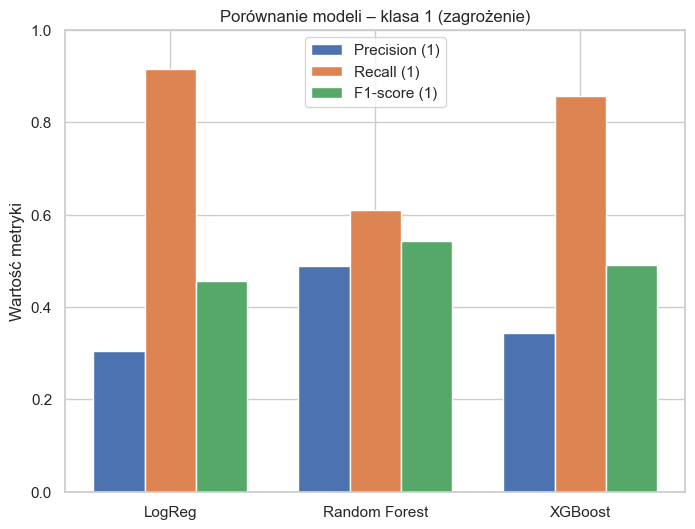

In [531]:
# Metryki dla klasy 1 (na podstawie Twoich wyników)
models = ["LogReg", "Random Forest", "XGBoost"]
precision = [0.304, 0.489, 0.343]
recall    = [0.916, 0.610, 0.857]
f1        = [0.456, 0.543, 0.490]

x = np.arange(len(models))  # pozycje na osi X
width = 0.25  # szerokość słupków

fig, ax = plt.subplots(figsize=(8,6))

# słupki
ax.bar(x - width, precision, width, label='Precision (1)')
ax.bar(x, recall, width, label='Recall (1)')
ax.bar(x + width, f1, width, label='F1-score (1)')

# opisy osi
ax.set_ylabel('Wartość metryki')
ax.set_title('Porównanie modeli – klasa 1 (zagrożenie)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0,1)
ax.legend()

plt.show()


Z wykresu wynika:

- Logistic Regression → najwyższy Recall, ale najniższa Precision.

- Random Forest → najlepsza Precision i F1, ale słabszy Recall.

- XGBoost → kompromis (Recall wysoki, Precision średni, F1 so

Dodam jeszcze drugi wykres → ogólna jakość rozróżniania klas (ROC-AUC) i skuteczność dla klasy rzadkiej (PR-AUC)

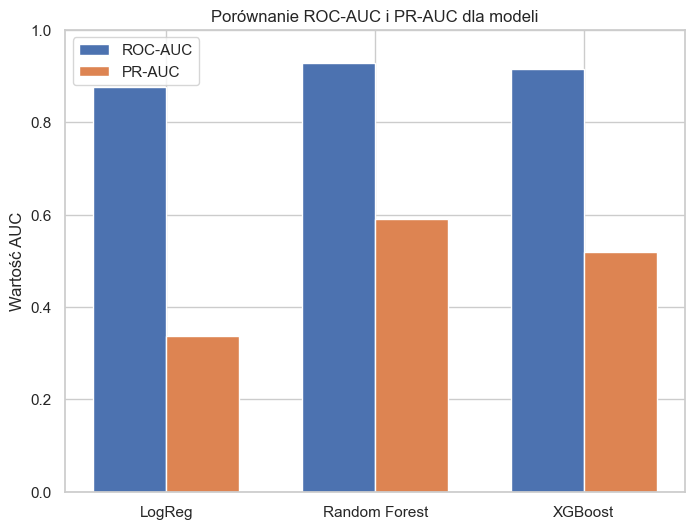

In [532]:
# Wyniki AUC (na podstawie obliczeń)
models = ["LogReg", "Random Forest", "XGBoost"]
roc_auc = [0.877, 0.928, 0.916]
pr_auc  = [0.338, 0.590, 0.520]

x = np.arange(len(models))  # pozycje na osi X
width = 0.35

fig, ax = plt.subplots(figsize=(8,6))

# słupki
ax.bar(x - width/2, roc_auc, width, label='ROC-AUC')
ax.bar(x + width/2, pr_auc, width, label='PR-AUC')

# opisy osi
ax.set_ylabel('Wartość AUC')
ax.set_title('Porównanie ROC-AUC i PR-AUC dla modeli')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0,1)
ax.legend()

plt.show()


Na wykresie widać:

ROC-AUC → wszystkie modele >0.87 (bardzo dobre), najlepszy Random Forest (0.928).

PR-AUC → wyraźne różnice: Random Forest (0.59) i XGBoost (0.52) znacznie przewyższają Logistic Regression (0.34).

# 6. Wnioski końcowe

## 6.1 Który model sprawdził się najlepiej?

### Logistic Regression

najwyższy Recall (0.916) → model prawie nie przeoczył zagrożeń (FN=148),

bardzo niska Precision (0.304) → ogromna liczba fałszywych alarmów (FP=3710).

### Random Forest

najwyższe Accuracy (0.900) i najlepsza Precision (0.489),

najmniej fałszywych alarmów (FP=1126),

ale przepuścił sporo zagrożeń (Recall=0.610, FN=689).

### XGBoost

kompromis pomiędzy dwoma podejściami,

Recall=0.857 (FN=253) → większość zagrożeń wykryta,

mniej fałszywych alarmów niż Logistic Regression (FP=2902 vs 3710),

metryki AUC: ROC-AUC=0.916, PR-AUC=0.520 → mocny wynik na niezbalansowanych danych.

 **Najlepszym kompromisem dla NASA jest XGBoost, bo wykrywa większość zagrożeń i jednocześnie ogranicza liczbę fałszywych alarmów czyli jest bezpieczny i pozwala priorytetyzować projekty badawcze**.

## 6.2 Jakie cechy są najważniejsze?

Analiza ważności cech (Random Forest i XGBoost) wskazała, że:

miss_distance (logarytmiczna odległość od Ziemi) → najważniejsza cecha,

relative_velocity (prędkość asteroidy) → druga najważniejsza,

est_diameter_avg (średnia średnica) → istotna, ale mniej niż odległość i prędkość,

absolute_magnitude → również wnosi informację.

 **Największe znaczenie mają odległość i prędkość, co jest zgodne z intuicją fizyczną (bliższe i szybsze obiekty są bardziej niebezpieczne)**.

## 6.3 Rekomendacje dla NASA

1. Wdrożyć model XGBoost jako główny system wykrywania potencjalnie niebezpiecznych asteroid.

2. Priorytet na Recall klasy 1 (zagrożenia) – nawet kosztem większej liczby fałszywych alarmów, ponieważ w bezpieczeństwie kosmicznym ważniejsze jest, aby nie przeoczyć groźnego obiektu.

3. Monitorować Precision – liczba fałszywych alarmów powinna być ograniczana (np. przez strojenie progu decyzyjnego).

4. Rozwijać zestaw cech – włączyć dodatkowe parametry orbitalne, aby poprawić skuteczność modeli.

5. Raportować także metryki AUC – ROC-AUC i PR-AUC dają lepszy obraz skuteczności modeli niż samo accuracy, szczególnie przy niezbalansowanych danych.


### Podsumowanie

***Najlepszym kompromisem między wykrywaniem zagrożeń a liczbą fałszywych alarmów okazał się **model XGBoost**, dlatego rekomendujemy go jako najodpowiedniejszy dla NASA***.


In [533]:
df.head()


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous,log_miss_distance,est_diameter_avg
0,3.587149,3.587149,-1.363907,0.795225,-2.348647,0,0.672529,3.587149
1,0.463515,0.463515,1.008978,1.090430,-1.218770,1,0.772412,0.463515
2,1.991814,1.991814,2.616875,0.569695,-1.968566,0,0.587758,1.991814
3,-0.103594,-0.103594,-0.921308,-0.520317,-0.458609,0,-0.002900,-0.103594
4,0.427365,0.427365,-0.210724,0.412072,-1.187673,1,0.523251,0.427365


W kolejnym kroku, dla pokazania praktycznego działania modelu, użyłam go do predykcji na całym dostępnym zbiorze (df).
Dzięki temu mogłam policzyć prawdopodobieństwo bycia potencjalnie niebezpieczną asteroidą (p_hazardous) oraz nadać etykietę 0/1 (pred_hazardous) dla wszystkich rekordów.
Ta predykcja nie służy do oceny jakości modelu, lecz do pokazania, jak model może wskazywać obiekty ryzykowne w praktyce.

In [534]:
proba = xgb.predict_proba(df[feature_cols])[:, 1]   # prawdopodobieństwo zagrożenia
pred  = xgb.predict(df[feature_cols])               # decyzja 0/1 przy progu domyślnym 0.5


In [535]:
df_pred = df.copy()
df_pred["p_hazardous"] = proba
df_pred["pred_hazardous"] = pred

df_pred.head(10)


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous,log_miss_distance,est_diameter_avg,p_hazardous,pred_hazardous
0,3.587149,3.587149,-1.363907,0.795225,-2.348647,0,0.672529,3.587149,0.014680,0
1,0.463515,0.463515,1.008978,1.090430,-1.218770,1,0.772412,0.463515,0.578387,1
2,1.991814,1.991814,2.616875,0.569695,-1.968566,0,0.587758,1.991814,0.705008,1
3,-0.103594,-0.103594,-0.921308,-0.520317,-0.458609,0,-0.002900,-0.103594,0.002758,0
4,0.427365,0.427365,-0.210724,0.412072,-1.187673,1,0.523251,0.427365,0.825728,1
5,-0.305094,-0.305094,-0.544407,0.157512,0.273911,0,0.407910,-0.305094,0.000022,0
6,0.148009,0.148009,-0.811987,-0.357728,-0.890519,0,0.114509,0.148009,0.873706,1
7,-0.409027,-0.409027,0.374664,0.807541,1.714764,0,0.676931,-0.409027,0.000028,0
8,0.746887,0.746887,0.338321,1.430351,-1.426087,0,0.874916,0.746887,0.323931,0
9,-0.072404,-0.072404,0.014157,0.057725,-0.527714,0,0.358218,-0.072404,0.360160,0


Aby sprawdzić, które obiekty model uważa za najbardziej niebezpieczne, posortowałam wszystkie rekordy oznaczone jako potencjalnie niebezpieczne (pred_hazardous = 1) według prawdopodobieństwa zagrożenia (p_hazardous) w kolejności malejącej.
Dzięki temu otrzymałam listę Top-10 asteroid z najwyższym prawdopodobieństwem kolizji z Ziemią według modelu XGBoost.
Takie zestawienie pozwala działowi badawczemu NASA priorytetyzować dalsze analizy – najpierw zajmując się obiektami o najwyższym przewidywanym ryzyku.

In [536]:
df_pred[df_pred["pred_hazardous"] == 1] \
    .sort_values("p_hazardous", ascending=False) \
    .head(10)


,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous,log_miss_distance,est_diameter_avg,p_hazardous,pred_hazardous
72600,0.083137,0.083137,-0.282031,-1.353883,-0.800681,1,-1.162237,0.083137,0.999844,1
7450,0.083137,0.083137,-0.339831,-1.488902,-0.800681,1,-1.677645,0.083137,0.999826,1
28463,0.927005,0.927005,-0.763945,-1.351631,-1.533201,1,-1.155755,0.927005,0.999783,1
52253,0.102277,0.102277,0.155174,-1.500515,-0.828324,1,-1.740097,0.102277,0.999772,1
55267,0.083137,0.083137,0.677530,-1.529068,-0.800681,1,-1.915649,0.083137,0.999765,1
31173,0.097425,0.097425,0.145239,-1.434580,-0.821413,1,-1.433062,0.097425,0.999759,1
52547,0.102277,0.102277,-0.086387,-1.452573,-0.828324,1,-1.506789,0.102277,0.999737,1
75159,0.488460,0.488460,-0.769195,-1.465089,-1.239502,1,-1.561981,0.488460,0.999732,1
57913,0.102277,0.102277,-0.263380,-1.331985,-0.828324,1,-1.101160,0.102277,0.999730,1
9134,0.300201,0.300201,0.709395,-1.347064,-1.066738,1,-1.142760,0.300201,0.999728,1


Po kilku nieudanych próbach zrezygnowałam z łączenia wyników modelu XGBoost z nazwami asteroid, ponieważ okazało się to zbyt skomplikowane i nie wnosiło wartości do analizy. Na etapie wstępnego przetwarzania usunęłam kolumny id i name, ponieważ jako początkująca uznałam je za zbędne dla trenowania modelu. Dopiero później zauważyłam, że ich zachowanie mogłoby ułatwić identyfikację asteroid w wynikach, jednak w tamtym momencie nie przewidziałam tej potrzeby. Nastepnym razem postąpie inaczej.